# Лабораторная работа  
## Имитационное моделирование по пособию «AnyLogic 8 за три дня»
### Реализация моделей в Google Colab

**Выполнила:** Манина В. С., группа ББИ2302, МТУСИ

**Цель работы:** изучить основные подходы имитационного моделирования и выполнить моделирование динамических систем в воспроизводимой вычислительной среде Google Colab.

В практическом пособии И. Григорьева рассматриваются три основные модели:
1. агентная модель потребительского рынка;
2. системно-динамическая модель распространения эпидемии;
3. дискретно-событийная модель небольшого заводского цеха.

В среде **AnyLogic** эти модели строятся графически с использованием агентов, диаграмм состояний, накопителей и потоков, библиотек процессов и трёхмерной анимации. В данном ноутбуке воспроизводится **аналитическая логика** этих моделей средствами Python. Визуальный интерфейс, 3D-анимация и файл проекта `.alp` в Google Colab не создаются, поскольку они относятся к возможностям самой программы AnyLogic.

**Основание для параметров моделей:**  
Григорьев И. *AnyLogic 8 за три дня: практическое пособие по имитационному моделированию*. 2024.


## 1. Используемые методы моделирования

| Метод | Модель в работе | Объект наблюдения | Основные результаты |
|---|---|---|---|
| Агентное моделирование | Вывод нового продукта на рынок | Отдельные потребители и их состояния | Динамика пользователей, заявок и повторных продаж |
| Системная динамика | Распространение эпидемии | Совокупности населения в состояниях SEIR | Пик инфекционных случаев и влияние интенсивности контактов |
| Дискретно-событийное моделирование | Производственный цех | Поддоны, погрузчики и станки | Выпуск продукции, загрузка ресурсов и очереди |

В пособии также рассматривается пешеходная модель аэропорта. Она опирается на пространственную разметку и специализированную библиотеку AnyLogic, поэтому в настоящей лабораторной работе не воспроизводится в Colab.


## 2. Подключение библиотек

Для выполнения работы не требуются дополнительные файлы данных. Все параметры берутся из постановок моделей, приведённых в учебном пособии. Результаты формируются при запуске ячеек ноутбука.


In [1]:
import warnings
warnings.filterwarnings('ignore')

from collections import deque
from itertools import count
import heapq

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

print('Библиотеки подключены. Случайные результаты воспроизводимы благодаря RANDOM_SEED = 42.')

Библиотеки подключены. Случайные результаты воспроизводимы благодаря RANDOM_SEED = 42.


# Часть I. Агентная модель потребительского рынка

## 3. Постановка модели

Модель описывает вывод нового продукта на рынок численностью **5000 человек**. Каждый человек представлен самостоятельным агентом-потребителем.

В модели используются состояния:

| Состояние | Содержание |
|---|---|
| `PotentialUser` | человек ещё не приобрёл продукт, но может принять решение о покупке |
| `WantsToBuy` | человек решил купить продукт и ожидает доставку |
| `User` | человек получил продукт и является его пользователем |

Параметры модели по пособию:

| Параметр | Значение | Смысл |
|---|---:|---|
| `AdEffectiveness` | 0.01 | интенсивность принятия решения о покупке под действием рекламы |
| `ContactRate` | 1 контакт в день | средняя интенсивность общения пользователя с другими людьми |
| `AdoptionFraction` | 0.01 | вероятность покупки после рекомендации |
| `DiscardTime` | 6 месяцев | срок эксплуатации продукта до повторной покупки |
| `MaxWaitingTime` | 7 дней | допустимое время ожидания доставки |
| `MaxDeliveryTime` | 25 дней | максимальный срок доставки |

В пособии срок доставки задаётся треугольным распределением `triangular(1, MaxDeliveryTime, 2)`. В Colab использовано соответствующее распределение `numpy.random.triangular(1, 2, MaxDeliveryTime)`. Для допустимого времени ожидания используется симметричная треугольная аппроксимация около среднего значения 7 дней с отклонением 15%.


In [2]:
POTENTIAL = 0
WAITING = 1
USER = 2

def simulate_market(
    population=5000,
    days=365,
    ad_effectiveness=0.01,
    contact_rate=1.0,
    adoption_fraction=0.01,
    discard_time=180,
    max_waiting_time=7,
    max_delivery_time=25,
    seed=42
):
    local_rng = np.random.default_rng(seed)
    state = np.full(population, POTENTIAL, dtype=np.int8)

    due_purchase = np.full(population, np.inf)
    due_cancel = np.full(population, np.inf)
    due_discard = np.full(population, np.inf)

    cumulative_sales = 0
    cancellations = 0
    requests_from_ad = 0
    requests_from_wom = 0
    history = []

    def begin_waiting(agent_ids, current_day):
        nonlocal state, due_purchase, due_cancel
        if len(agent_ids) == 0:
            return
        state[agent_ids] = WAITING
        delivery_delay = np.ceil(
            local_rng.triangular(1, 2, max_delivery_time, size=len(agent_ids))
        ).astype(int)
        wait_left = max(0.1, max_waiting_time * 0.85)
        wait_right = max_waiting_time * 1.15
        waiting_delay = np.ceil(
            local_rng.triangular(wait_left, max_waiting_time, wait_right, size=len(agent_ids))
        ).astype(int)
        due_purchase[agent_ids] = current_day + delivery_delay
        due_cancel[agent_ids] = current_day + waiting_delay

    for day in range(days + 1):
        # Отказы от покупки из-за длительной доставки
        cancel_ids = np.where(
            (state == WAITING) &
            (due_cancel <= day) &
            (due_cancel < due_purchase)
        )[0]
        if len(cancel_ids):
            state[cancel_ids] = POTENTIAL
            due_purchase[cancel_ids] = np.inf
            due_cancel[cancel_ids] = np.inf
            cancellations += len(cancel_ids)

        # Завершённая доставка и совершение покупки
        purchase_ids = np.where(
            (state == WAITING) &
            (due_purchase <= day) &
            (due_purchase <= due_cancel)
        )[0]
        if len(purchase_ids):
            state[purchase_ids] = USER
            due_purchase[purchase_ids] = np.inf
            due_cancel[purchase_ids] = np.inf
            due_discard[purchase_ids] = day + discard_time
            cumulative_sales += len(purchase_ids)

        # Истечение срока эксплуатации товара: пользователь хочет замену
        discard_ids = np.where((state == USER) & (due_discard <= day))[0]
        if len(discard_ids):
            due_discard[discard_ids] = np.inf
            begin_waiting(discard_ids, day)

        history.append({
            'Day': day,
            'PotentialUser': int(np.sum(state == POTENTIAL)),
            'WantsToBuy': int(np.sum(state == WAITING)),
            'User': int(np.sum(state == USER)),
            'Cumulative_Sales': cumulative_sales,
            'Cancellations': cancellations
        })

        if day == days:
            break

        # Воздействие рекламы на потенциальных пользователей
        potential_ids = np.where(state == POTENTIAL)[0]
        ad_probability = 1 - np.exp(-ad_effectiveness)
        ad_selected = potential_ids[
            local_rng.random(len(potential_ids)) < ad_probability
        ]
        requests_from_ad += len(ad_selected)

        # Рекомендации от текущих пользователей
        users_count = int(np.sum(state == USER))
        contact_events = local_rng.poisson(users_count * contact_rate)
        wom_selected = np.array([], dtype=int)

        if contact_events > 0:
            targets = local_rng.integers(0, population, size=contact_events)
            eligible = targets[state[targets] == POTENTIAL]
            if len(eligible):
                successful = eligible[
                    local_rng.random(len(eligible)) < adoption_fraction
                ]
                wom_selected = np.unique(successful)
                requests_from_wom += len(wom_selected)

        new_requests = np.unique(np.concatenate([ad_selected, wom_selected]))
        begin_waiting(new_requests, day)

    history_df = pd.DataFrame(history)
    metrics = {
        'Пользователи на конец периода': int(history_df.iloc[-1]['User']),
        'Накопленные продажи с повторными покупками': cumulative_sales,
        'Отказы из-за длительной доставки': cancellations,
        'Заявки под действием рекламы': requests_from_ad,
        'Заявки после рекомендаций': requests_from_wom
    }
    return history_df, metrics

market_history, market_metrics = simulate_market()

display(pd.DataFrame(
    {'Показатель': list(market_metrics.keys()), 'Значение': list(market_metrics.values())}
))
display(market_history.head())
display(market_history.tail())

,Показатель,Значение
0,Пользователи на конец периода,3369
1,Накопленные продажи с повторными покупками,6518
2,Отказы из-за длительной доставки,8256
3,Заявки под действием рекламы,8511
4,Заявки после рекомендаций,3347


,Day,PotentialUser,WantsToBuy,User,Cumulative_Sales,Cancellations
0,0,5000,0,0,0,0
1,1,4956,44,0,0,0
2,2,4900,98,2,2,0
3,3,4855,137,8,8,0
4,4,4790,192,18,18,0


,Day,PotentialUser,WantsToBuy,User,Cumulative_Sales,Cancellations
361,361,1451,203,3346,6449,8188
362,362,1450,200,3350,6466,8205
363,363,1449,194,3357,6482,8226
364,364,1429,211,3360,6497,8241
365,365,1423,208,3369,6518,8256


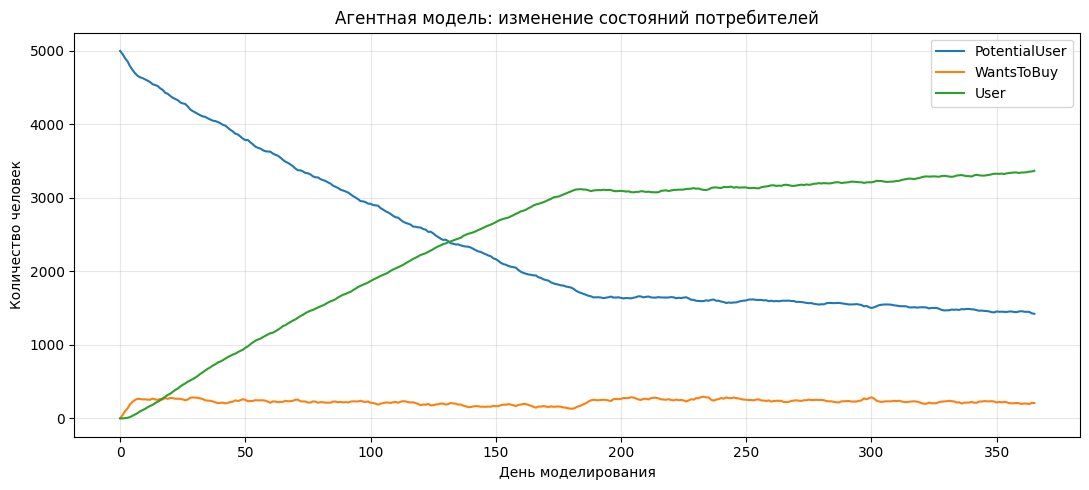

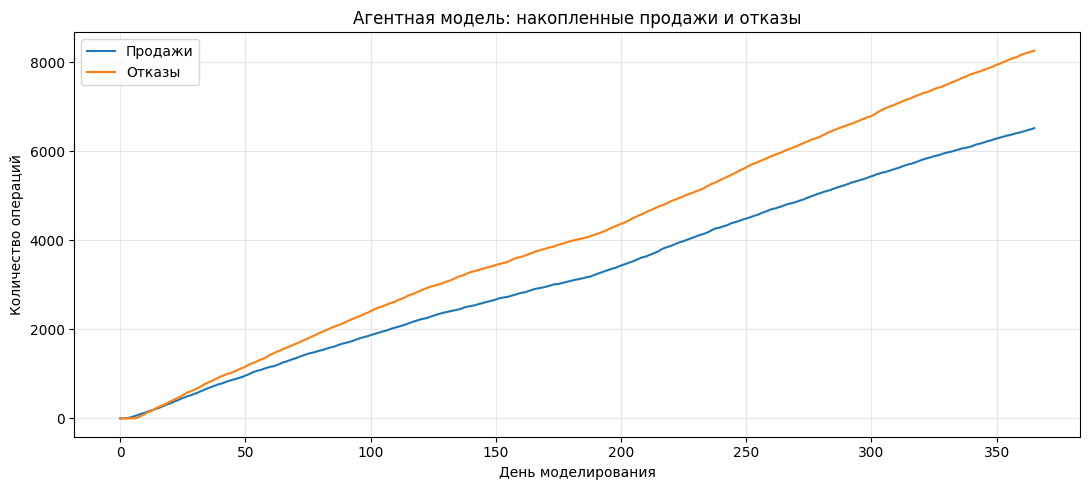

In [3]:
plt.figure(figsize=(11, 5))
plt.plot(market_history['Day'], market_history['PotentialUser'], label='PotentialUser')
plt.plot(market_history['Day'], market_history['WantsToBuy'], label='WantsToBuy')
plt.plot(market_history['Day'], market_history['User'], label='User')
plt.title('Агентная модель: изменение состояний потребителей')
plt.xlabel('День моделирования')
plt.ylabel('Количество человек')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
plt.plot(market_history['Day'], market_history['Cumulative_Sales'], label='Продажи')
plt.plot(market_history['Day'], market_history['Cancellations'], label='Отказы')
plt.title('Агентная модель: накопленные продажи и отказы')
plt.xlabel('День моделирования')
plt.ylabel('Количество операций')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Эксперимент сравнения прогонов

В пособии сравнение прогонов строится при изменении параметра `ContactRate`. Повторим эксперимент и проверим, как интенсивность общения пользователей влияет на проникновение продукта на рынок.


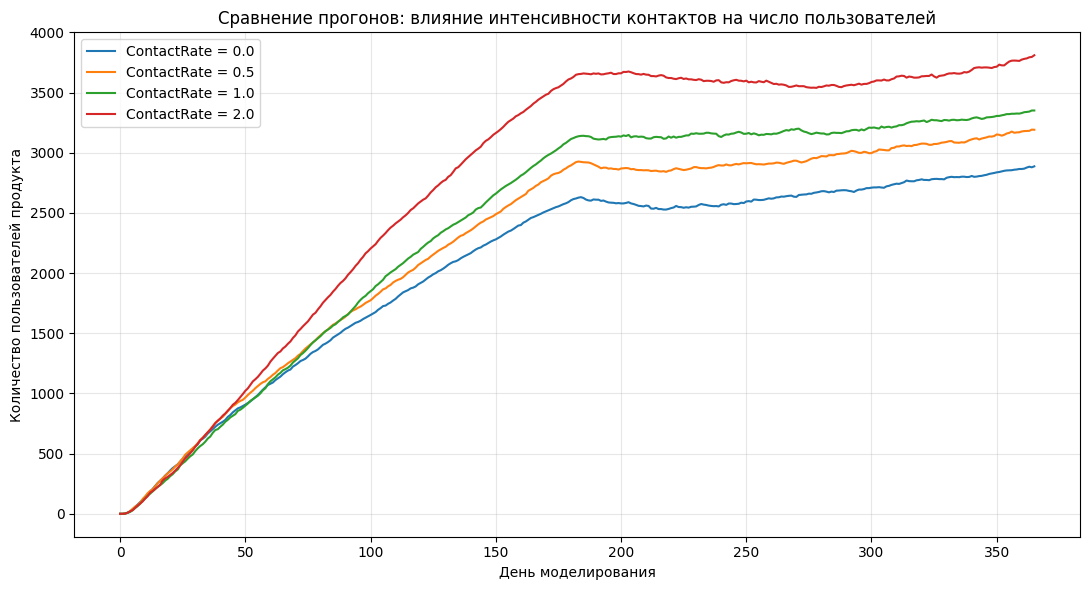

,ContactRate,Пользователи на конец периода,Накопленные продажи с повторными покупками,Отказы из-за длительной доставки,Заявки под действием рекламы,Заявки после рекомендаций
0,0.00,2887,5548,6959,10002,0
1,0.50,3191,6154,7556,9247,1711
2,1.00,3351,6521,8386,8557,3412
3,2.00,3810,7499,9078,7175,5977


In [4]:
contact_rates = [0.0, 0.5, 1.0, 2.0]
market_scenarios = []
market_summaries = []

plt.figure(figsize=(11, 6))

for index, rate in enumerate(contact_rates):
    history, metrics = simulate_market(contact_rate=rate, seed=RANDOM_SEED + index)
    history['ContactRate'] = rate
    market_scenarios.append(history)
    market_summaries.append({
        'ContactRate': rate,
        **metrics
    })
    plt.plot(history['Day'], history['User'], label=f'ContactRate = {rate}')

plt.title('Сравнение прогонов: влияние интенсивности контактов на число пользователей')
plt.xlabel('День моделирования')
plt.ylabel('Количество пользователей продукта')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

market_scenarios_df = pd.concat(market_scenarios, ignore_index=True)
market_summaries_df = pd.DataFrame(market_summaries)

display(market_summaries_df)

In [5]:
base_users = int(
    market_summaries_df.loc[market_summaries_df['ContactRate'] == 0.0,
                            'Пользователи на конец периода'].iloc[0]
)
high_contact_users = int(
    market_summaries_df.loc[market_summaries_df['ContactRate'] == 2.0,
                            'Пользователи на конец периода'].iloc[0]
)

display(Markdown(
    f'''### Вывод по агентной модели

При отсутствии рекомендаций к концу года продуктом пользуются **{base_users:,}** человек.  
При увеличении интенсивности контактов до двух контактов в день число пользователей составляет **{high_contact_users:,}** человек.

Модель показывает, что коммуникация между потребителями ускоряет распространение продукта. Одновременно наличие доставки и отказов делает итог менее идеализированным: решение о покупке не всегда превращается в совершённую продажу.'''
))

### Вывод по агентной модели

При отсутствии рекомендаций к концу года продуктом пользуются **2,887** человек.  
При увеличении интенсивности контактов до двух контактов в день число пользователей составляет **3,810** человек.

Модель показывает, что коммуникация между потребителями ускоряет распространение продукта. Одновременно наличие доставки и отказов делает итог менее идеализированным: решение о покупке не всегда превращается в совершённую продажу.

# Часть II. Системно-динамическая модель распространения эпидемии

## 5. Постановка модели SEIR

Модель включает четыре накопителя:

| Накопитель | Содержание |
|---|---|
| `Susceptible` | восприимчивые к заражению люди |
| `Exposed` | заражённые в инкубационном периоде |
| `Infectious` | люди в активной заразной стадии |
| `Recovered` | выздоровевшие и получившие иммунитет |

Параметры из пособия:

| Параметр | Значение |
|---|---:|
| `TotalPopulation` | 10 000 человек |
| `Infectivity` | 0.6 |
| `ContactRateInfectious` | 1.25 контакта в день |
| `AverageIncubationTime` | 10 дней |
| `AverageIllnessDuration` | 15 дней |
| Начальное число `Infectious` | 1 человек |

Потоки модели рассчитываются по формулам:

\[
ExposedRate = Infectious \times ContactRateInfectious \times Infectivity \times \frac{Susceptible}{TotalPopulation}
\]

\[
InfectiousRate = \frac{Exposed}{AverageIncubationTime}
\]

\[
RecoveredRate = \frac{Infectious}{AverageIllnessDuration}
\]


In [6]:
def simulate_seir(
    total_population=10000,
    infectivity=0.6,
    contact_rate_infectious=1.25,
    average_incubation_time=10,
    average_illness_duration=15,
    days=300
):
    initial = [total_population - 1, 0, 1, 0]

    def equations(time, state):
        susceptible, exposed, infectious, recovered = state
        exposed_rate = (
            infectious * contact_rate_infectious * infectivity *
            susceptible / total_population
        )
        infectious_rate = exposed / average_incubation_time
        recovered_rate = infectious / average_illness_duration
        return [
            -exposed_rate,
            exposed_rate - infectious_rate,
            infectious_rate - recovered_rate,
            recovered_rate
        ]

    time_points = np.arange(0, days + 1)
    solution = solve_ivp(
        equations,
        [0, days],
        initial,
        t_eval=time_points,
        rtol=1e-8,
        atol=1e-8
    )

    result = pd.DataFrame({
        'Day': solution.t,
        'Susceptible': solution.y[0],
        'Exposed': solution.y[1],
        'Infectious': solution.y[2],
        'Recovered': solution.y[3]
    })
    return result

seir_history = simulate_seir()
peak_row = seir_history.loc[seir_history['Infectious'].idxmax()]

print(f'День максимума инфекционных случаев: {int(peak_row["Day"])}')
print(f'Максимальное число инфекционных случаев: {peak_row["Infectious"]:,.0f}')
print(f'Выздоровевших к 300-му дню: {seir_history.iloc[-1]["Recovered"]:,.0f}')

display(seir_history.head())

День максимума инфекционных случаев: 59
Максимальное число инфекционных случаев: 3,742
Выздоровевших к 300-му дню: 10,000


,Day,Susceptible,Exposed,Infectious,Recovered
0,0,"9,999.00",0.00,1.00,0.00
1,1,"9,998.27",0.70,0.97,0.07
2,2,"9,997.53",1.33,1.01,0.13
3,3,"9,996.74",1.96,1.10,0.20
4,4,"9,995.86",2.61,1.25,0.28


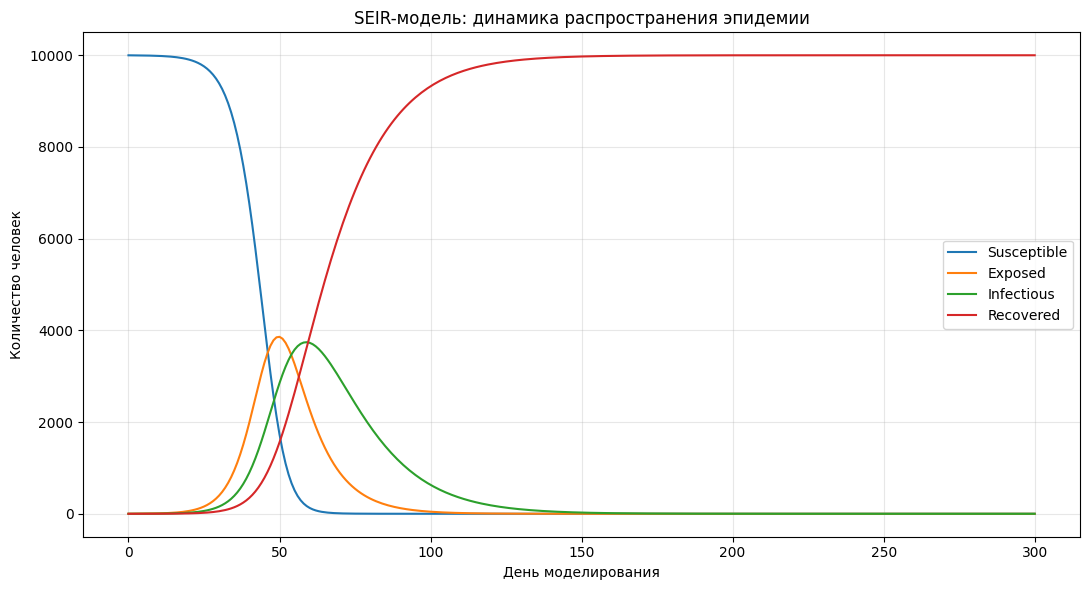

In [7]:
plt.figure(figsize=(11, 6))
for variable in ['Susceptible', 'Exposed', 'Infectious', 'Recovered']:
    plt.plot(seir_history['Day'], seir_history[variable], label=variable)

plt.title('SEIR-модель: динамика распространения эпидемии')
plt.xlabel('День моделирования')
plt.ylabel('Количество человек')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Эксперимент варьирования параметра `ContactRateInfectious`

В AnyLogic Cloud в пособии предлагается изменять интенсивность контактов заражённых людей от **0.3** до **2.0** с шагом **0.1** и сравнивать полученные кривые. Ниже тот же эксперимент выполнен вычислительно.


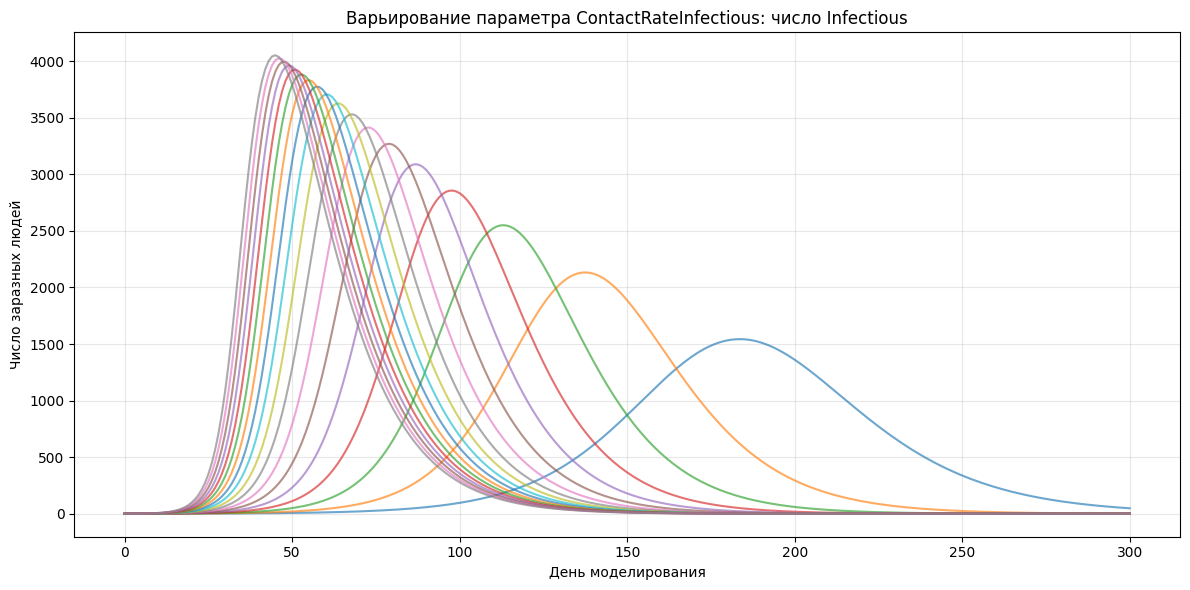

,ContactRateInfectious,День пика,Пиковое число Infectious,Recovered на день 300
0,0.30,184,"1,542.84","9,075.95"
1,0.40,137,"2,131.95","9,692.67"
2,0.50,113,"2,549.82","9,882.70"
3,0.60,98,"2,855.47","9,953.66"
4,0.70,87,"3,088.42","9,981.41"
5,0.80,79,"3,269.40","9,992.49"
6,0.90,73,"3,413.00","9,996.95"
7,1.00,68,"3,530.01","9,998.76"
8,1.10,64,"3,625.96","9,999.50"
9,1.20,60,"3,705.81","9,999.79"


In [8]:
contact_values = np.round(np.arange(0.3, 2.01, 0.1), 1)
seir_variation_results = []

plt.figure(figsize=(12, 6))

for value in contact_values:
    scenario = simulate_seir(contact_rate_infectious=value)
    peak = scenario.loc[scenario['Infectious'].idxmax()]
    seir_variation_results.append({
        'ContactRateInfectious': value,
        'День пика': int(peak['Day']),
        'Пиковое число Infectious': peak['Infectious'],
        'Recovered на день 300': scenario.iloc[-1]['Recovered']
    })
    plt.plot(scenario['Day'], scenario['Infectious'], alpha=0.65)

plt.title('Варьирование параметра ContactRateInfectious: число Infectious')
plt.xlabel('День моделирования')
plt.ylabel('Число заразных людей')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

seir_variation_df = pd.DataFrame(seir_variation_results)
display(seir_variation_df.round(2))

In [9]:
lowest = seir_variation_df.iloc[0]
highest = seir_variation_df.iloc[-1]

display(Markdown(
    f'''### Вывод по варьированию параметра

При `ContactRateInfectious = {lowest["ContactRateInfectious"]:.1f}` пиковое число заразных людей составляет **{lowest["Пиковое число Infectious"]:,.0f}**.  
При `ContactRateInfectious = {highest["ContactRateInfectious"]:.1f}` пиковое число заразных людей составляет **{highest["Пиковое число Infectious"]:,.0f}**, а пик наступает на **{int(highest["День пика"])}-й день**.

Чем выше интенсивность контактов, тем быстрее инфекция распространяется в популяции и тем выше нагрузка в период пика. Эксперимент показывает практическое значение ограничений контактов при управлении эпидемическим процессом.'''
))

### Вывод по варьированию параметра

При `ContactRateInfectious = 0.3` пиковое число заразных людей составляет **1,543**.  
При `ContactRateInfectious = 2.0` пиковое число заразных людей составляет **4,051**, а пик наступает на **45-й день**.

Чем выше интенсивность контактов, тем быстрее инфекция распространяется в популяции и тем выше нагрузка в период пика. Эксперимент показывает практическое значение ограничений контактов при управлении эпидемическим процессом.

## 7. Демонстрация калибровки параметров

В пособии калибровка выполняется по историческим данным из файла `HistoricData.txt`. Этот файл к работе не приложен. Поэтому ниже показан **учебный алгоритм калибровки**: создаётся набор условно наблюдаемых значений с небольшим случайным шумом, после чего модель восстанавливает параметры `Infectivity` и `ContactRateInfectious`.

Этот блок демонстрирует процедуру, но не заменяет калибровку по реальным наблюдениям.


,Параметр,Заданное значение для учебных наблюдений,Оценка после калибровки
0,Infectivity,0.55,0.54
1,ContactRateInfectious,1.10,1.13


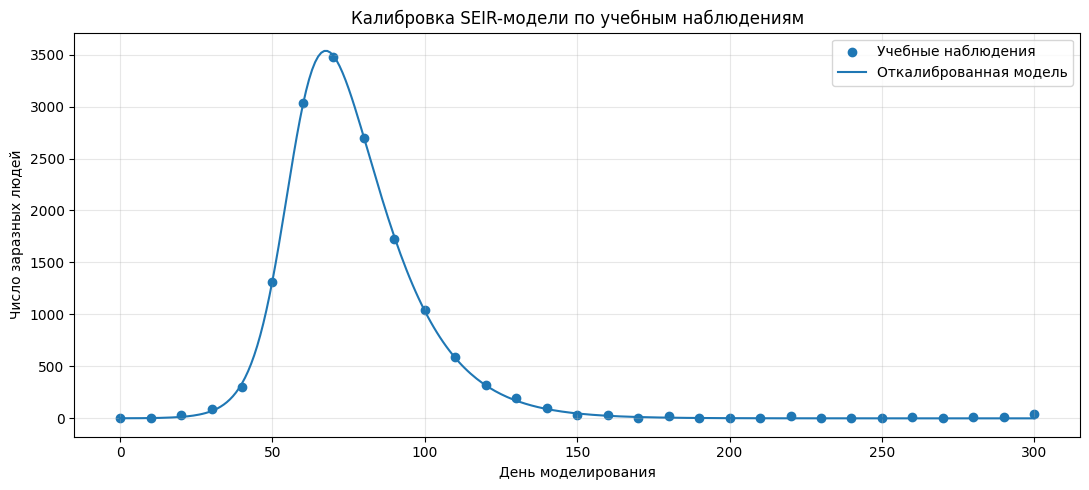

In [10]:
observed_days = np.arange(0, 301, 10)
reference_history = simulate_seir(
    infectivity=0.55,
    contact_rate_infectious=1.10
)
reference_values = reference_history.loc[
    reference_history['Day'].isin(observed_days), 'Infectious'
].to_numpy()

calibration_rng = np.random.default_rng(RANDOM_SEED)
observed_infectious = np.maximum(
    0,
    reference_values + calibration_rng.normal(0, 20, size=len(reference_values))
)

def calibration_residuals(parameters):
    infectivity, contact_rate = parameters
    model_history = simulate_seir(
        infectivity=infectivity,
        contact_rate_infectious=contact_rate
    )
    model_values = model_history.loc[
        model_history['Day'].isin(observed_days), 'Infectious'
    ].to_numpy()
    return model_values - observed_infectious

calibration = least_squares(
    calibration_residuals,
    x0=[0.6, 1.25],
    bounds=([0.1, 0.3], [1.0, 2.0])
)

estimated_infectivity, estimated_contact_rate = calibration.x
calibrated_history = simulate_seir(
    infectivity=estimated_infectivity,
    contact_rate_infectious=estimated_contact_rate
)

calibration_table = pd.DataFrame({
    'Параметр': ['Infectivity', 'ContactRateInfectious'],
    'Заданное значение для учебных наблюдений': [0.55, 1.10],
    'Оценка после калибровки': [estimated_infectivity, estimated_contact_rate]
})

display(calibration_table.round(4))

plt.figure(figsize=(11, 5))
plt.scatter(observed_days, observed_infectious, label='Учебные наблюдения')
plt.plot(
    calibrated_history['Day'],
    calibrated_history['Infectious'],
    label='Откалиброванная модель'
)
plt.title('Калибровка SEIR-модели по учебным наблюдениям')
plt.xlabel('День моделирования')
plt.ylabel('Число заразных людей')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Часть III. Дискретно-событийная модель производственного цеха

## 8. Постановка модели

По пособию моделируется небольшой заводской цех:

- раз в час прибывает фура;
- при начале разгрузки создаётся **60 поддонов** с заготовками;
- для транспортировки используется **5 автопогрузчиков**;
- после помещения на склад поддон хранится в течение времени `triangular(15, 20, 30)` минут;
- затем поддон доставляется к одному из **двух станков с ЧПУ**;
- обработка заготовки на станке занимает **1 минуту**.

В AnyLogic время движения погрузчика определяется нарисованной транспортной сетью и физическим расстоянием между узлами. В Colab такой пространственной схемы нет. Поэтому для движения погрузчика используется прозрачное допущение: одна операция перевозки занимает случайное время `triangular(0.5, 1.0, 1.5)` минут. Это допущение требуется только для численного воспроизведения очередей и загрузки ресурсов.


In [11]:
class JobShopSimulation:
    def __init__(
        self,
        horizon=480,
        truck_interval=60,
        pallets_per_truck=60,
        forklifts=5,
        cnc_machines=2,
        cnc_processing_time=1.0,
        seed=42
    ):
        self.horizon = horizon
        self.truck_interval = truck_interval
        self.pallets_per_truck = pallets_per_truck
        self.forklifts = forklifts
        self.cnc_machines = cnc_machines
        self.cnc_processing_time = cnc_processing_time
        self.rng = np.random.default_rng(seed)

        self.events = []
        self.event_counter = count()
        self.receiving_queue = deque()
        self.retrieve_queue = deque()
        self.cnc_queue = deque()

        self.forklifts_busy = 0
        self.cnc_busy = 0
        self.pallet_counter = 0

        self.arrival_time = {}
        self.cnc_ready_time = {}
        self.store_waits = []
        self.cnc_waits = []

        self.arrived = 0
        self.completed = 0
        self.forklift_busy_time = 0.0
        self.cnc_busy_time = 0.0
        self.records = []

    def schedule(self, time, event_type, payload=None):
        heapq.heappush(
            self.events,
            (time, next(self.event_counter), event_type, payload)
        )

    def transport_duration(self):
        return float(self.rng.triangular(0.5, 1.0, 1.5))

    def storage_duration(self):
        return float(self.rng.triangular(15, 20, 30))

    def record(self, time):
        self.records.append({
            'Minute': time,
            'Receiving_Queue': len(self.receiving_queue),
            'Retrieve_Queue': len(self.retrieve_queue),
            'CNC_Queue': len(self.cnc_queue),
            'Forklifts_Busy': self.forklifts_busy,
            'CNC_Busy': self.cnc_busy,
            'Completed_Products': self.completed
        })

    def start_forklift_tasks(self, time):
        while self.forklifts_busy < self.forklifts and (
            self.retrieve_queue or self.receiving_queue
        ):
            if self.retrieve_queue:
                pallet_id = self.retrieve_queue.popleft()
                task_type = 'retrieve_done'
            else:
                pallet_id = self.receiving_queue.popleft()
                self.store_waits.append(time - self.arrival_time[pallet_id])
                task_type = 'store_done'

            duration = self.transport_duration()
            self.forklifts_busy += 1
            self.forklift_busy_time += max(0, min(time + duration, self.horizon) - time)
            self.schedule(time + duration, task_type, pallet_id)

    def start_cnc_tasks(self, time):
        while self.cnc_busy < self.cnc_machines and self.cnc_queue:
            pallet_id = self.cnc_queue.popleft()
            self.cnc_waits.append(time - self.cnc_ready_time[pallet_id])
            self.cnc_busy += 1
            self.cnc_busy_time += max(
                0,
                min(time + self.cnc_processing_time, self.horizon) - time
            )
            self.schedule(time + self.cnc_processing_time, 'cnc_done', pallet_id)

    def run(self):
        for arrival_time in np.arange(0, self.horizon, self.truck_interval):
            self.schedule(float(arrival_time), 'truck_arrival')

        self.record(0)

        while self.events:
            time, _, event_type, payload = heapq.heappop(self.events)
            if time > self.horizon:
                break

            if event_type == 'truck_arrival':
                for _ in range(self.pallets_per_truck):
                    pallet_id = self.pallet_counter
                    self.pallet_counter += 1
                    self.arrival_time[pallet_id] = time
                    self.receiving_queue.append(pallet_id)
                    self.arrived += 1
                self.start_forklift_tasks(time)

            elif event_type == 'store_done':
                self.forklifts_busy -= 1
                self.schedule(time + self.storage_duration(), 'storage_ready', payload)
                self.start_forklift_tasks(time)

            elif event_type == 'storage_ready':
                self.retrieve_queue.append(payload)
                self.start_forklift_tasks(time)

            elif event_type == 'retrieve_done':
                self.forklifts_busy -= 1
                self.cnc_ready_time[payload] = time
                self.cnc_queue.append(payload)
                self.start_cnc_tasks(time)
                self.start_forklift_tasks(time)

            elif event_type == 'cnc_done':
                self.cnc_busy -= 1
                self.completed += 1
                self.start_cnc_tasks(time)

            self.record(time)

        dynamics = pd.DataFrame(self.records).sort_values('Minute')
        metrics = {
            'Поступило поддонов': self.arrived,
            'Выпущено изделий за горизонт моделирования': self.completed,
            'Незавершённое производство': self.arrived - self.completed,
            'Среднее ожидание разгрузки, мин': np.mean(self.store_waits) if self.store_waits else 0,
            'Среднее ожидание станка, мин': np.mean(self.cnc_waits) if self.cnc_waits else 0,
            'Загрузка погрузчиков, %': self.forklift_busy_time / (self.forklifts * self.horizon) * 100,
            'Загрузка станков с ЧПУ, %': self.cnc_busy_time / (self.cnc_machines * self.horizon) * 100
        }
        return dynamics, metrics

job_shop = JobShopSimulation()
jobshop_dynamics, jobshop_metrics = job_shop.run()

display(pd.DataFrame(
    {'Показатель': list(jobshop_metrics.keys()), 'Значение': list(jobshop_metrics.values())}
).round(2))

display(jobshop_dynamics.head())

,Показатель,Значение
0,Поступило поддонов,480.00
1,Выпущено изделий за горизонт моделирования,480.00
2,Незавершённое производство,0.00
3,"Среднее ожидание разгрузки, мин",5.46
4,"Среднее ожидание станка, мин",6.08
5,"Загрузка погрузчиков, %",40.00
6,"Загрузка станков с ЧПУ, %",50.00


,Minute,Receiving_Queue,Retrieve_Queue,CNC_Queue,Forklifts_Busy,CNC_Busy,Completed_Products
0,0.00,0,0,0,0,0,0
1,0.00,55,0,0,5,0,0
2,0.72,54,0,0,5,0,0
3,0.97,53,0,0,5,0,0
4,1.11,52,0,0,5,0,0


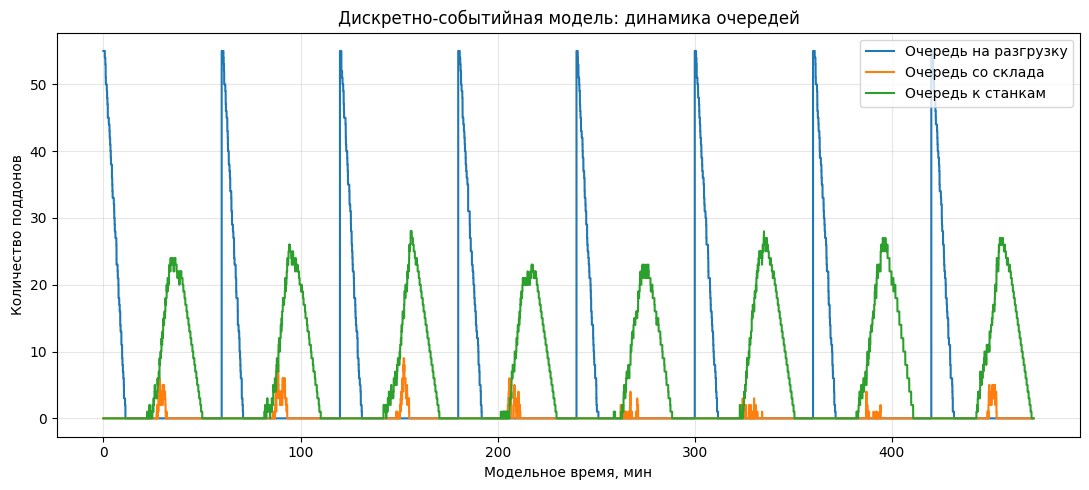

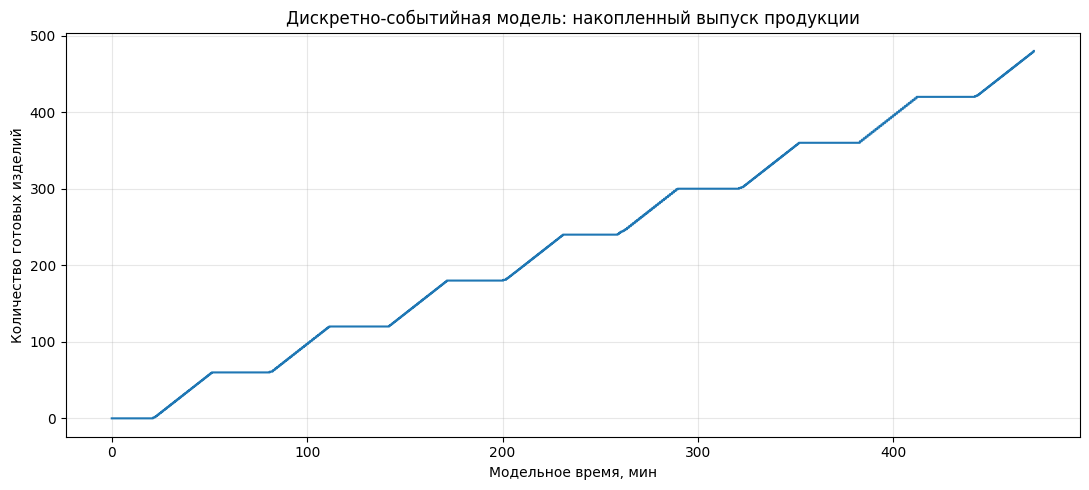

In [12]:
jobshop_plot = (
    jobshop_dynamics.groupby('Minute', as_index=False)
                    .last()
                    .sort_values('Minute')
)

plt.figure(figsize=(11, 5))
plt.step(jobshop_plot['Minute'], jobshop_plot['Receiving_Queue'],
         where='post', label='Очередь на разгрузку')
plt.step(jobshop_plot['Minute'], jobshop_plot['Retrieve_Queue'],
         where='post', label='Очередь со склада')
plt.step(jobshop_plot['Minute'], jobshop_plot['CNC_Queue'],
         where='post', label='Очередь к станкам')
plt.title('Дискретно-событийная модель: динамика очередей')
plt.xlabel('Модельное время, мин')
plt.ylabel('Количество поддонов')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
plt.step(jobshop_plot['Minute'], jobshop_plot['Completed_Products'], where='post')
plt.title('Дискретно-событийная модель: накопленный выпуск продукции')
plt.xlabel('Модельное время, мин')
plt.ylabel('Количество готовых изделий')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Эксперимент с ресурсами производственного цеха

Проведём серию прогонов, изменяя количество погрузчиков и станков с ЧПУ. Такой анализ позволяет понять, увеличение какого ресурса действительно сокращает очереди и повышает выпуск.


In [13]:
resource_scenarios = []

for forklifts in [3, 5, 7]:
    for cnc_machines in [1, 2, 3]:
        simulation = JobShopSimulation(
            forklifts=forklifts,
            cnc_machines=cnc_machines,
            seed=RANDOM_SEED + forklifts * 10 + cnc_machines
        )
        _, metrics = simulation.run()
        resource_scenarios.append({
            'Погрузчики': forklifts,
            'Станки с ЧПУ': cnc_machines,
            **metrics
        })

resource_scenarios_df = pd.DataFrame(resource_scenarios)
display(resource_scenarios_df.round(2))

throughput_table = resource_scenarios_df.pivot(
    index='Погрузчики',
    columns='Станки с ЧПУ',
    values='Выпущено изделий за горизонт моделирования'
)

print('Выпуск изделий по сочетаниям количества ресурсов')
display(throughput_table)

,Погрузчики,Станки с ЧПУ,Поступило поддонов,Выпущено изделий за горизонт моделирования,Незавершённое производство,"Среднее ожидание разгрузки, мин","Среднее ожидание станка, мин","Загрузка погрузчиков, %","Загрузка станков с ЧПУ, %"
0,3,1,480,458,22,9.61,16.45,66.91,95.47
1,3,2,480,480,0,9.43,3.17,66.72,50.00
2,3,3,480,480,0,9.57,0.16,66.48,33.33
3,5,1,480,458,22,5.52,20.51,40.15,95.48
4,5,2,480,480,0,5.50,6.22,40.19,50.00
5,5,3,480,480,0,5.44,1.82,39.71,33.33
6,7,1,480,459,21,3.78,22.07,28.57,95.64
7,7,2,480,480,0,3.78,7.30,28.73,50.00
8,7,3,480,480,0,3.78,2.97,28.72,33.33


Выпуск изделий по сочетаниям количества ресурсов


Станки с ЧПУ,1,2,3
Погрузчики,,,
3,458,480,480
5,458,480,480
7,459,480,480


In [14]:
best_output = resource_scenarios_df.sort_values(
    ['Выпущено изделий за горизонт моделирования',
     'Среднее ожидание разгрузки, мин'],
    ascending=[False, True]
).iloc[0]

display(Markdown(
    f'''### Вывод по модели производственного цеха

В базовом сценарии с 5 погрузчиками и 2 станками за восьмичасовой горизонт
завершено **{int(jobshop_metrics["Выпущено изделий за горизонт моделирования"]):,}** изделий
из **{int(jobshop_metrics["Поступило поддонов"]):,}** поступивших поддонов.

Среди проверенных комбинаций наибольший выпуск с учётом сокращения ожидания
достигнут при конфигурации: **{int(best_output["Погрузчики"])} погрузчиков**
и **{int(best_output["Станки с ЧПУ"])} станка(ов) с ЧПУ**.

Эксперимент показывает назначение дискретно-событийного моделирования:
оно позволяет оценивать очереди, загрузку ресурсов и производительность
до изменения реальной производственной системы.'''
))

### Вывод по модели производственного цеха

В базовом сценарии с 5 погрузчиками и 2 станками за восьмичасовой горизонт
завершено **480** изделий
из **480** поступивших поддонов.

Среди проверенных комбинаций наибольший выпуск с учётом сокращения ожидания
достигнут при конфигурации: **7 погрузчиков**
и **2 станка(ов) с ЧПУ**.

Эксперимент показывает назначение дискретно-событийного моделирования:
оно позволяет оценивать очереди, загрузку ресурсов и производительность
до изменения реальной производственной системы.

# 10. Экспорт результатов

После выполнения ноутбука формируются следующие файлы:

| Файл | Содержание |
|---|---|
| `market_dynamics.csv` | базовая динамика состояний потребительского рынка |
| `market_scenarios.csv` | результаты сравнения прогонов агентной модели |
| `seir_dynamics.csv` | динамика базовой модели эпидемии |
| `seir_parameter_variation.csv` | показатели сценариев варьирования контактов |
| `jobshop_dynamics.csv` | динамика очередей и выпуска цеха |
| `jobshop_resource_scenarios.csv` | результаты сравнения конфигураций ресурсов |


In [15]:
market_history.to_csv('market_dynamics.csv', index=False, encoding='utf-8-sig')
market_scenarios_df.to_csv('market_scenarios.csv', index=False, encoding='utf-8-sig')
seir_history.to_csv('seir_dynamics.csv', index=False, encoding='utf-8-sig')
seir_variation_df.to_csv('seir_parameter_variation.csv', index=False, encoding='utf-8-sig')
jobshop_dynamics.to_csv('jobshop_dynamics.csv', index=False, encoding='utf-8-sig')
resource_scenarios_df.to_csv('jobshop_resource_scenarios.csv', index=False, encoding='utf-8-sig')

print('Файлы результатов успешно сохранены в рабочей папке ноутбука.')

Файлы результатов успешно сохранены в рабочей папке ноутбука.


# Заключение

В лабораторной работе воспроизведены три основных подхода к имитационному моделированию, представленные в пособии по AnyLogic.

Агентная модель потребительского рынка позволила описать поведение отдельных покупателей, переходы между состояниями, влияние рекламы и рекомендаций, задержку доставки и повторные покупки. Сравнение прогонов показало, что увеличение интенсивности контактов ускоряет распространение продукта на рынке.

Системно-динамическая SEIR-модель представила распространение инфекции через накопители и потоки. На её основе был выполнен эксперимент варьирования интенсивности контактов и продемонстрирована процедура калибровки параметров. Полученные результаты показывают, что изменение интенсивности контактов существенно влияет на сроки и масштаб эпидемического пика.

Дискретно-событийная модель производственного цеха позволила проследить движение поддонов через операции разгрузки, хранения, транспортировки и обработки на станках. Сценарный анализ ресурсов показал, как количество погрузчиков и станков отражается на выпуске, очередях и загрузке оборудования.

Таким образом, имитационное моделирование даёт возможность исследовать сложные системы в виртуальной среде, сравнивать сценарии и обосновывать решения без рискованных вмешательств в реальную деятельность.


# Ответы на вопросы по выполненной работе

**1. Почему для потребительского рынка выбран агентный подход?**  
Потому что итоговая динамика рынка формируется из поведения отдельных людей: они видят рекламу, получают рекомендации, ожидают доставку, отказываются от покупки или приобретают товар повторно.

**2. В чём смысл накопителей и потоков в модели эпидемии?**  
Накопители отражают количество людей в каждом состоянии заболевания, а потоки показывают скорость перехода из одного состояния в другое. Такая структура позволяет анализировать динамику процесса на уровне всей популяции.

**3. Почему производственный цех моделируется как дискретно-событийная система?**  
Работа цеха представляет собой последовательность событий и операций: прибытие фуры, разгрузка, хранение, перевозка, ожидание ресурса и обработка на станке. Главные показатели здесь — очереди, загрузка ресурсов и выпуск.

**4. Чем реализация в Colab отличается от модели AnyLogic?**  
Colab воспроизводит расчётную логику и эксперименты, но не заменяет графический редактор AnyLogic, диаграммы в формате `.alp`, встроенную 3D-анимацию и специализированные библиотеки пространственного или пешеходного моделирования.

**5. В чём практическая ценность результатов?**  
Модели позволяют оценить последствия управленческих решений до их внедрения: подобрать маркетинговый сценарий, оценить воздействие ограничений контактов или определить достаточность производственных ресурсов.


## Скачивание CSV-файлов в Google Colab

После выполнения всех ячеек можно скачать сформированные таблицы с результатами.


In [16]:
try:
    from google.colab import files
    for filename in [
        'market_dynamics.csv',
        'market_scenarios.csv',
        'seir_dynamics.csv',
        'seir_parameter_variation.csv',
        'jobshop_dynamics.csv',
        'jobshop_resource_scenarios.csv'
    ]:
        files.download(filename)
except ImportError:
    print('Файлы находятся в рабочей папке ноутбука.')

Файлы находятся в рабочей папке ноутбука.
